# Creation of the line plots with data

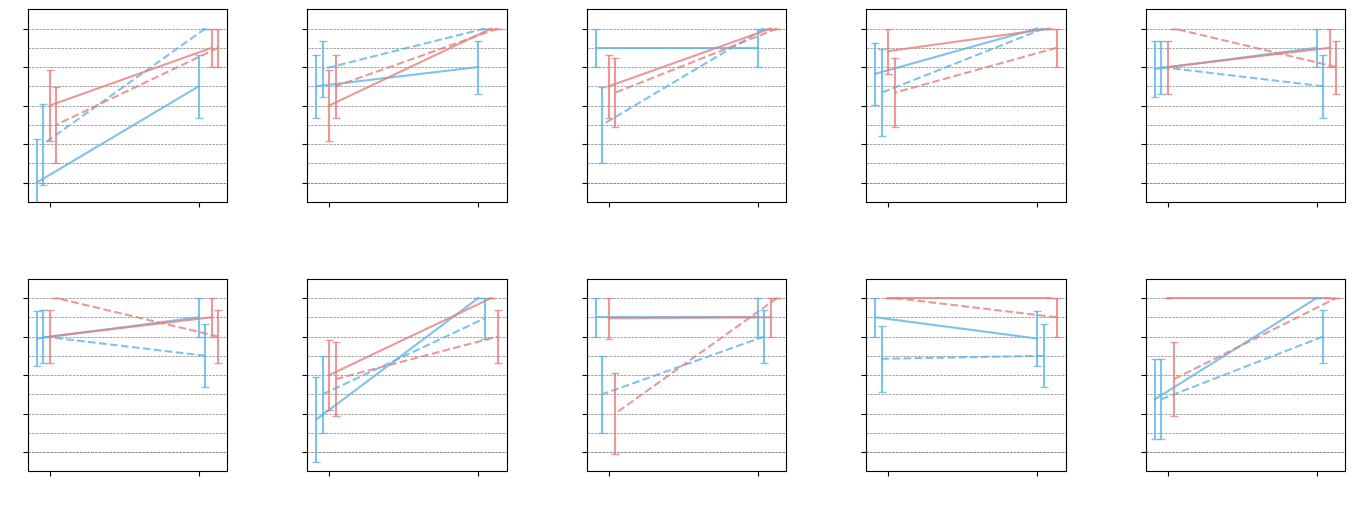

In [ ]:
# create an array of paths for the graphs created in the loop
paths = ['/content/drive/MyDrive/Experimental_data/03_RANDOM_1_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-04_14h40.54.589.csv',
         '/content/drive/MyDrive/Experimental_data/04_RANDOM_2_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_14h26.22.381.csv',
         '/content/drive/MyDrive/Experimental_data/05_RANDOM_3_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_15h03.39.716.csv',
         '/content/drive/MyDrive/Experimental_data/06_RANDOM_4_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_13h51.56.087.csv',
         '/content/drive/MyDrive/Experimental_data/07_RANDOM_5_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_18h46.26.064.csv',
         '/content/drive/MyDrive/Experimental_data/09_RANDOM_2_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-13_19h00.14.866.csv',
         '/content/drive/MyDrive/Experimental_data/10_RANDOM_3_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-13_17h16.42.809.csv',
         '/content/drive/MyDrive/Experimental_data/11_RANDOM_4_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-14_10h09.37.881.csv',
         '/content/drive/MyDrive/Experimental_data/12_RANDOM_5_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-17_18h42.29.462.csv',
         '/content/drive/MyDrive/Experimental_data/13_RANDOM_1_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-18_16h35.42.026.csv'
]
c = 0 # counter for the array
k = 3 # counter for the even / odd participants which requires a differnt correct answer code for the recognition
fig, axs = plt.subplots(nrows=2, ncols=5, figsize=(17,6))
all_data = pd.DataFrame() # dataframe with all data to calculate grand mean

# loop though rows and colums to create the graphs
for i, ax in enumerate(axs.flatten()):
  if i >= len(paths):  # check if index i is greater than or equal to the length of paths
    break  # exit the loop

  if k in [3, 5, 7, 9, 11]: # odd participants with normal response buttons
    exp_data = preprocess_data_2N(paths[c]) # see preprocess code

  if k in [4,6,10,12,13]: # even participants with reversed response buttons
    exp_data = preprocess_data_2R(paths[c])

  exp_data = exp_data.dropna(subset=['key_resp_dec.rt'])
  grouped_data = group_data_exp(exp_data) #
  all_data = pd.concat([all_data, grouped_data])
  line_plot_acc(grouped_data, ax)
  c += 1
  k += 1

  if k == 8:
    continue

plt.subplots_adjust(wspace=0.4, hspace=0.4)
#fig.suptitle('Mean accuracy per condition of individual participants', family = 'sans-serif', fontsize=12)
#fig.text(0.075, 0.5, 'Accuracy', va='center', family = 'sans-serif', rotation='vertical')

plt.show()
fig.savefig('accuracy_plots.eps', format='eps')

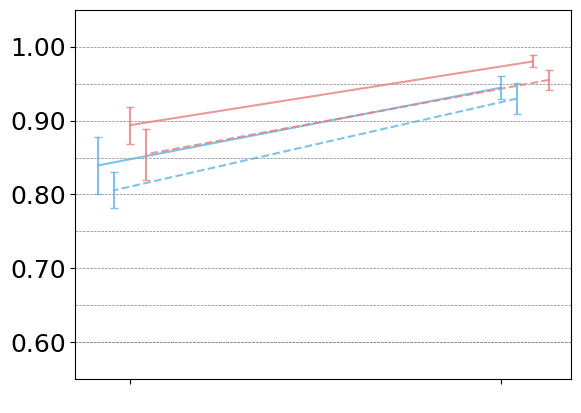

In [ ]:
# create empty dataframe with the factors and depended measures
mean_data = pd.DataFrame(columns=['stim_diff', 'stim_dur', 'stim_fam', 'sem_exp_rt', 'sem_exp_acc'])
fig, ax = plt.subplots()

# determine the condition from combination of the factors stim difficulty, stim duration and stim familiarty
for stim_diff in all_data['stim_diff'].unique():
    for stim_dur in all_data['stim_dur'].unique():
         for stim_fam in all_data['stim_fam'].unique():
            conditions = all_data[(all_data['stim_diff'] == stim_diff) &
                          (all_data['stim_dur'] == stim_dur) &
                          (all_data['stim_fam'] == stim_fam) &
                          (~all_data['mean_exp_rt'].isna()) &  # exlude missing values from aggregated data
                          (~all_data['mean_exp_acc'].isna())]
            # calculate the mean reaction time and accuracy for each condition (combination of factors)
            mean_exp_rt = conditions['mean_exp_rt'].mean()
            std_exp_rt = conditions['std_exp_rt'].mean()
            sem_exp_rt = conditions['mean_exp_rt'].sem()
            mean_exp_acc = conditions['mean_exp_acc'].mean()
            std_exp_acc = conditions['std_exp_acc'].mean()
            sem_exp_acc = conditions['mean_exp_acc'].sem()
            # add means to dataframe
            mean_data = mean_data.append({'stim_diff': stim_diff,
                                            'stim_dur': stim_dur,
                                            'stim_fam': stim_fam,
                                            'mean_exp_rt': mean_exp_rt,
                                            'mean_exp_acc': mean_exp_acc,
                                            'std_exp_rt' : std_exp_rt,
                                            'std_exp_acc': std_exp_acc,
                                            'sem_exp_rt' : sem_exp_rt,
                                            'sem_exp_acc' : sem_exp_acc},
                                            ignore_index=True)

line_plot_acc(mean_data, ax)
#plt.title('Mean accuracy per condition across participants', family = 'sans-serif', fontsize=12)
fig.savefig('mean_acc_plot.eps', format='eps')


# Creation of plot for reaction times

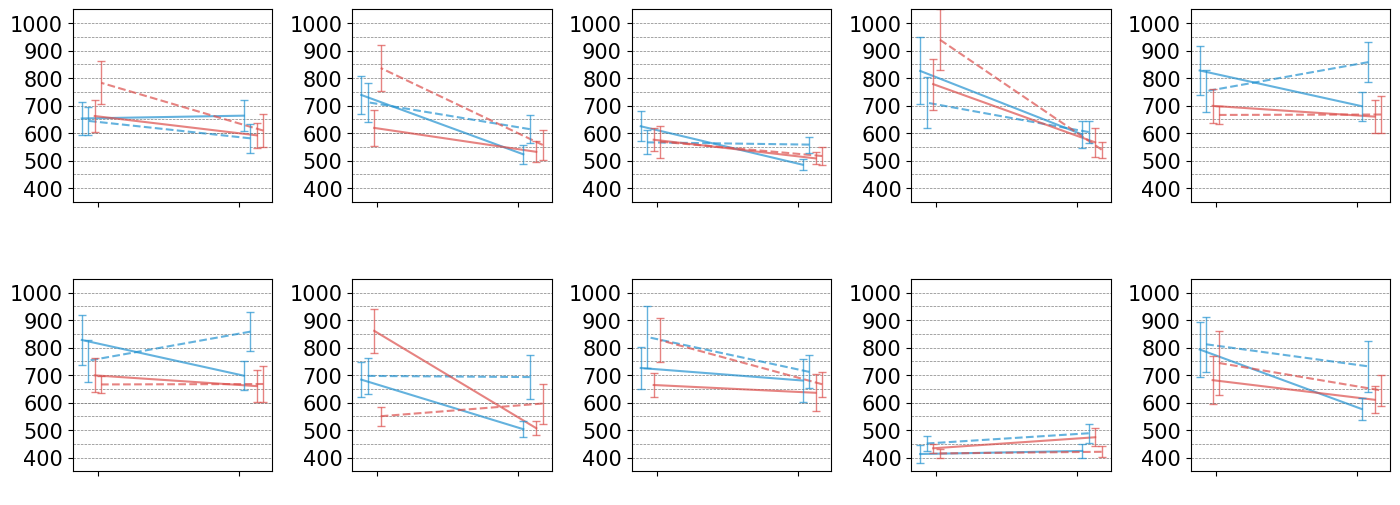

In [ ]:
c = 0 # counter for the array
k = 3 # counter for the even / odd participants which requires a differnt correct answer code for the recognition
fig, axs = plt.subplots(nrows=2, ncols=5, figsize=(17, 6), edgecolor = 'black')
all_data = pd.DataFrame() # dataframe with all data to calculate grand mean

# loop though rows and colums to create the graphs
for i, ax in enumerate(axs.flatten()):
  if i >= len(paths):  # check if index i is greater than or equal to the length of paths
    break  # exit the loop

  if k in [3, 5, 7, 9, 11]: # odd participants with normal response buttons
    exp_data = preprocess_data_2N(paths[c]) # see preprocess code

  if k in [4,6,10,12,13]: # even participants with reversed response buttons
    exp_data = preprocess_data_2R(paths[c])

  grouped_data = group_data_exp(exp_data)
  all_data = pd.concat([all_data, grouped_data])
  line_plot_rt(grouped_data, ax)
  c += 1
  k += 1

  if k == 8:
    continue

plt.subplots_adjust(wspace=0.4, hspace=0.4)
#fig.suptitle('Mean reaction time per condition of individual participants', family = 'sans-serif', fontsize=12)
#fig.text(0.08, 0.5, 'Reaction time (ms)', va='center', family = 'sans-serif', rotation='vertical')

fig.savefig('rt_plots.eps', format='eps')
plt.show()

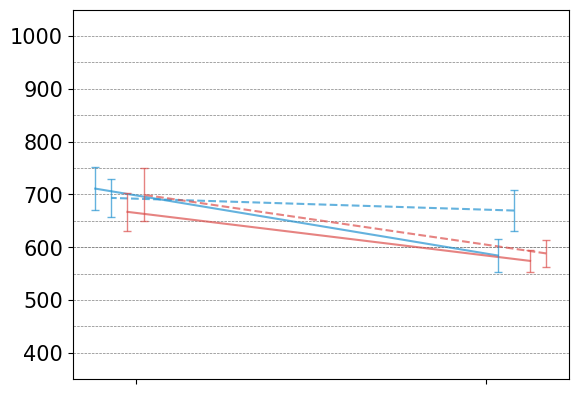

In [ ]:
# create empty dataframe with the factors and depended measures
mean_data = pd.DataFrame(columns=['stim_diff', 'stim_dur', 'stim_fam', 'sem_exp_rt', 'sem_exp_acc'])
fig, ax = plt.subplots()

# determine the condition from combination of the factors stim difficulty, stim duration and stim familiarty
for stim_diff in all_data['stim_diff'].unique():
    for stim_dur in all_data['stim_dur'].unique():
         for stim_fam in all_data['stim_fam'].unique():
            conditions = all_data[(all_data['stim_diff'] == stim_diff) &
                          (all_data['stim_dur'] == stim_dur) &
                          (all_data['stim_fam'] == stim_fam) &
                          (~all_data['mean_exp_rt'].isna()) &  # exlude missing values from aggregated data
                          (~all_data['mean_exp_acc'].isna())]
            # calculate the mean reaction time and accuracy for each condition (combination of factors)
            mean_exp_rt = conditions['mean_exp_rt'].mean()
            std_exp_rt = conditions['std_exp_rt'].mean()
            sem_exp_rt = conditions['mean_exp_rt'].sem()
            mean_exp_acc = conditions['mean_exp_acc'].mean()
            std_exp_acc = conditions['std_exp_acc'].mean()
            sem_exp_acc = conditions['mean_exp_acc'].sem()
            # add means to dataframe
            mean_data = mean_data.append({'stim_diff': stim_diff,
                                            'stim_dur': stim_dur,
                                            'stim_fam': stim_fam,
                                            'mean_exp_rt': mean_exp_rt,
                                            'mean_exp_acc': mean_exp_acc,
                                            'std_exp_rt' : std_exp_rt,
                                            'std_exp_acc': std_exp_acc,
                                            'sem_exp_rt' : sem_exp_rt,
                                            'sem_exp_acc' : sem_exp_acc},
                                            ignore_index=True)

line_plot_rt(mean_data, ax)
#plt.ylabel("reaction time (ms)")
#plt.title('Mean reaction time per condition across participants', family = 'sans-serif', fontsize=12)
fig.savefig('mean_rt_plot.eps', format='eps')

# Recognition test plots

<ipython-input-7-86aa51807b54>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  data_recog_df = data_recog_df.append({'stim_fam': stim_fam,
<ipython-input-7-86aa51807b54>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  data_recog_df = data_recog_df.append({'stim_fam': stim_fam,
<ipython-input-7-86aa51807b54>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  data_recog_df = data_recog_df.append({'stim_fam': stim_fam,
<ipython-input-7-86aa51807b54>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  data_recog_df = data_recog_df.append({'stim_fam': stim_fam,
<ipython-input-7-86aa51807b54>:26: FutureWarning: The frame.append method is dep

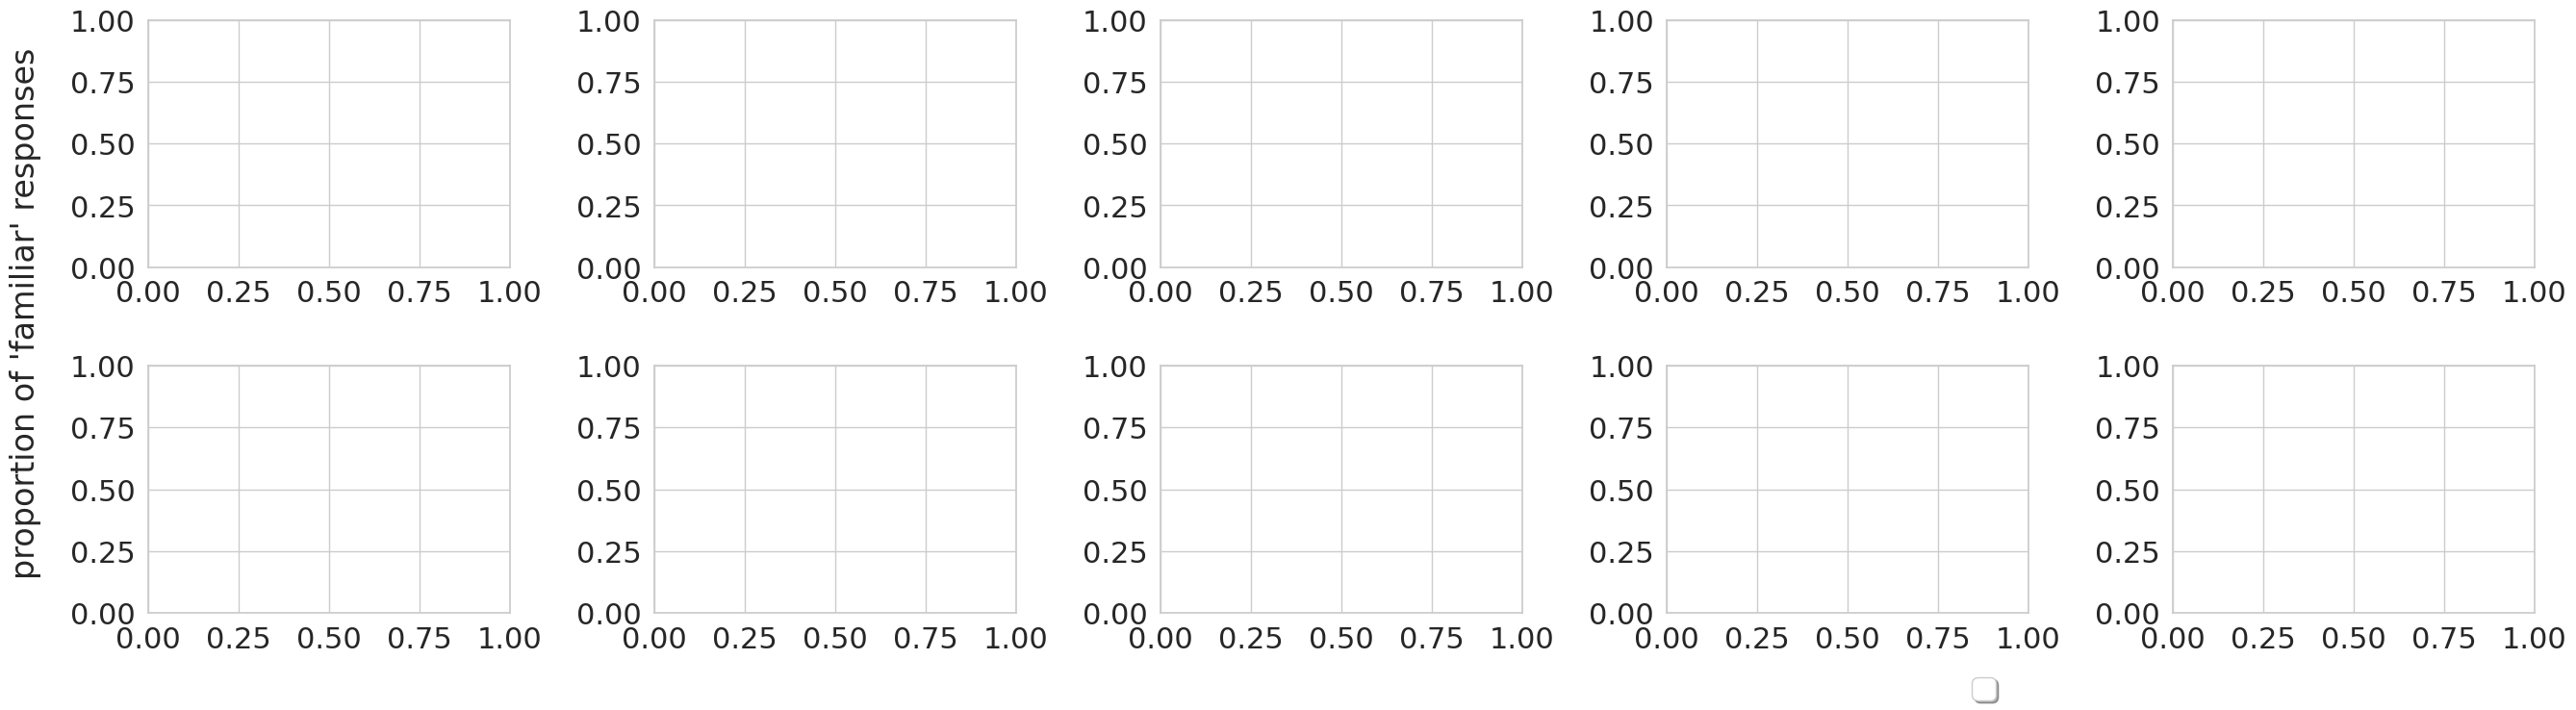

,stim_fam,mean_recog_rt,sem_recog_rt
0,distractor,2.112849,0.047239
1,novel,2.079515,0.046153
2,familiar,1.998635,0.060646
0,familiar,2.720131,0.084913
1,distractor,3.053192,0.111796
2,novel,2.854472,0.094575
0,familiar,2.195600,0.015008
1,distractor,2.197134,0.017336
2,novel,2.181285,0.015947
0,distractor,2.399615,0.048394


In [ ]:
paths = ['/content/drive/MyDrive/Experimental_data/03_RANDOM_1_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-04_14h40.54.589.csv',
         '/content/drive/MyDrive/Experimental_data/04_RANDOM_2_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_14h26.22.381.csv',
         '/content/drive/MyDrive/Experimental_data/05_RANDOM_3_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_15h03.39.716.csv',
         '/content/drive/MyDrive/Experimental_data/06_RANDOM_4_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_13h51.56.087.csv',
         '/content/drive/MyDrive/Experimental_data/07_RANDOM_5_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_18h46.26.064.csv',
         '/content/drive/MyDrive/Experimental_data/09_RANDOM_2_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-13_19h00.14.866.csv',
         '/content/drive/MyDrive/Experimental_data/10_RANDOM_3_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-13_17h16.42.809.csv',
         '/content/drive/MyDrive/Experimental_data/11_RANDOM_4_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-14_10h09.37.881.csv',
         '/content/drive/MyDrive/Experimental_data/12_RANDOM_5_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-17_18h42.29.462.csv',
         '/content/drive/MyDrive/Experimental_data/13_RANDOM_1_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-18_16h35.42.026.csv'
]
c = 0 # counter for the array
k = 3 # counter for the even / odd participants which requires a differnt correct answer code for the recognition
fig, axs = plt.subplots(nrows=2, ncols=5, figsize=(32, 8))
all_data_recog = pd.DataFrame() # dataframe with all data to calculate grand mean

# loop though rows and colums to create the graphs
for i, ax in enumerate(axs.flatten()):
  if i >= len(paths):  # check if index i is greater than or equal to the length of paths
    break  # exit the loop

  if k in [3, 5, 7, 9, 11]: # odd participants with normal response buttons
    exp_data = preprocess_data_2N(paths[c]) # see preprocess code

  if k in [4,6,10,12,13]: # even participants with reversed response buttons
    exp_data = preprocess_data_2R(paths[c])

  grouped_data = group_data_recog(exp_data) #
  all_data_recog = pd.concat([all_data_recog, grouped_data])
  #recog_plot(grouped_data, ax)
  c += 1
  k += 1

  if k == 8:
    continue

ax.legend(loc='upper right', bbox_to_anchor=(-0.45, -0.2),
          fancybox=True, shadow=True, ncol=1)
plt.subplots_adjust(wspace=0.4, hspace=0.4)
fig.text(0.08, 0.5, "proportion of 'familiar' responses", va='center', rotation='vertical')
plt.show()

display(all_data_recog[['stim_fam','mean_recog_rt', 'sem_recog_rt']])

,stim_fam,mean_recog_rt,mean_recog_acc,std_recog_rt,std_recog_acc,sem_recog_rt,sem_recog_acc,prop_recog_ans,std_recog_ans,sem_recog_ans
0,distractor,2.049383,0.527052,0.450770,0.467156,0.051971,0.053867,0.472948,0.467156,0.053867
1,familiar,1.960331,0.644551,0.402235,0.420132,0.046075,0.048168,0.644551,0.420132,0.048168
2,novel,2.019155,0.467666,0.418048,0.468794,0.048050,0.053735,0.467666,0.468794,0.053735


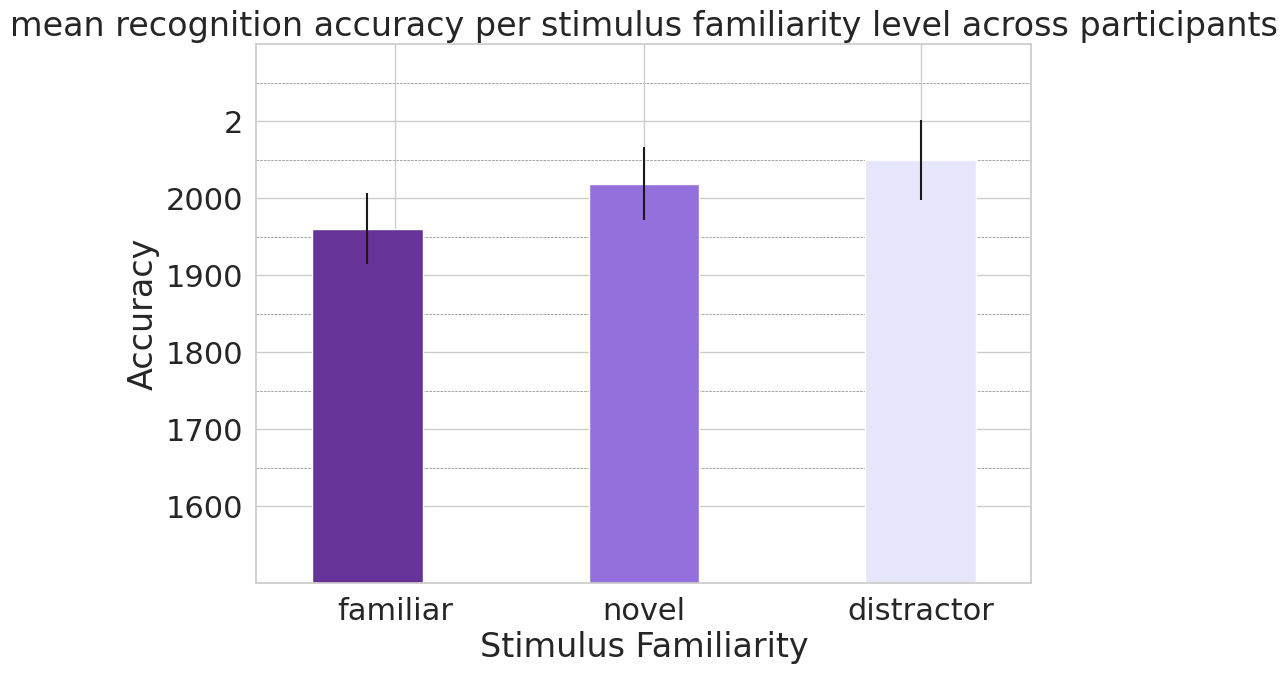

In [ ]:
all_recog_grouped = all_data_recog.groupby('stim_fam').mean().reset_index()
recog_plot(all_recog_grouped)
plt.title("mean recognition accuracy per stimulus familiarity level across participants")
plt.ylabel("Accuracy")

display(all_recog_grouped)

[0.62513527 0.80380979 0.6018486  0.82220088 0.66674866 0.7972877
 0.61776416 0.66709899 0.77089336 0.80166358]
[1.61226564 1.63214384 1.63898181 1.75415156 1.81949264 1.80701597
 1.61740998 1.70277328 1.73912158 1.81344557]
[2.61212058 2.80627407 2.64135446 2.66988771 2.73341107 2.82236247
 2.67352308 2.7552637  2.81495272 2.67437046]


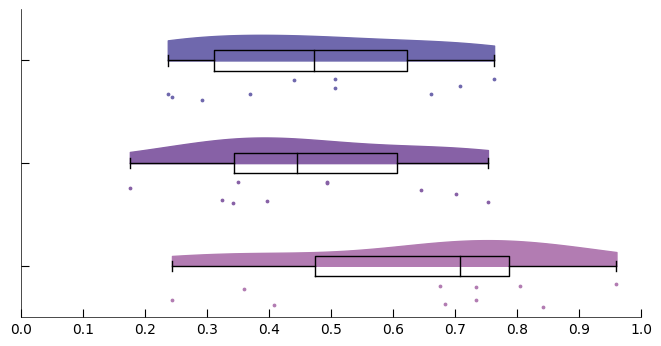

In [ ]:
data = all_data_recog
plt.style.use('default')
fig, ax = plt.subplots(figsize=(8,4))
# Step 1: get the x and y data
x1 = data.loc[data['stim_fam'] == 'familiar', 'prop_recog_ans'].values
x2 = data.loc[data['stim_fam'] == 'novel', 'prop_recog_ans'].values
x3 = data.loc[data['stim_fam'] == 'distractor', 'prop_recog_ans'].values
data_x = [x1, x2, x3]
#y = data['stim_fam'].map({'familiar': 0.0, 'novel': 0.5, 'distractor': 1.0})
# boxplot
boxplot_colors = ['palegoldenrod', 'khaki', 'darkkhaki']
boxplot_widths = [0.2, 0.2, 0.2]
medianprops = dict(color="black",linewidth=1)
bp = ax.boxplot(data_x, patch_artist = False, vert = False, widths=boxplot_widths, medianprops=medianprops)
#for patch, color in zip(bp['boxes'], boxplot_colors):
  #patch.set_facecolor(color)
  #patch.set_alpha(0.5)
# violin plots
violin_colors = ['#B27CB2', '#8761A6', '#6F68AD']
vp = ax.violinplot(data_x, points=500, showmeans=False, showextrema=False, showmedians=False, vert=False)
# for seeing only upper half of the violin
for idx, b in enumerate(vp['bodies']):
  m = np.mean(b.get_paths()[0].vertices[:, 0])
  b.get_paths()[0].vertices[:, 1] = np.clip(b.get_paths()[0].vertices[:, 1], idx+1, idx+2)
  b.set_color(violin_colors[idx])
  b.set_alpha(1)
# scatterplots
scatter_colors = ['#B27CB2', '#8761A6', '#6F68AD']
y_ticks = np.arange(1, 4)
y_offsets = [-0.25, -0.25, -0.25]
for idx, groups in enumerate(data_x):
  y = np.full(len(groups), y_ticks[idx])
  y = y.astype(float)
  jitter = np.random.uniform(low=-0.15, high=0.075, size=len(groups))  # Add jitter
  y += y_offsets[idx] + jitter
  plt.scatter(groups, y, s=3, c=scatter_colors[idx])
  print(y)

plt.yticks(np.arange(1,4,1), [' ', ' ', ' '])
plt.xticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
ax.tick_params(length = 6, direction = 'in')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
for axis in ['bottom','left']:
    ax.spines[axis].set_linewidth(.5)
for tick in ax.get_xticklabels():
    tick.set_fontname("Calibri")
#plt.xlabel ('Reaction time (s)')
#plt.title('Raincloud plot of distribution of reaction times per familiarity condition \nacross participants on the recognition test')

fig.savefig('recog_plots.eps', format='eps')

# data preprocessing in python

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

In [ ]:
def preprocess_data_2N(csv_path):  # meaning that in the recognition test 'a' is familiar response and 'l' is not familiar
    # Read the CSV file using pandas
    data = pd.read_csv(csv_path)

    # select only the colums containing the parameters or the data
    data = data[['img_name', 'img_cat', 'stim_nr', 'stim_diff', 'stim_cat', 'stim_dur', 'stim_fam', 'stim_pos', 'dist', 'training_key_resp.corr', 'training_key_resp_2.corr', 'key_resp_dec.corr', 'key_resp_dec.rt', 'fam_dec_key_resp.keys', 'fam_dec_key_resp.rt', 'participant', 'session']]

    # make sure the factors levels are strings without extra spaces
    data['stim_dur'] = data['stim_dur'].replace({1.0: 'short', 2.0: 'long'})
    data['stim_dur'] = data['stim_dur'].replace({"1.0": 'short', "2.0": 'long'})
    data['stim_dur'] = data['stim_dur'].replace({" 1.0": 'short', " 2.0": 'long'})
    data['stim_diff'] = data['stim_diff'].replace({' challenge': 'challenge', ' control': 'control'})
    data['stim_fam'] = data['stim_fam'].replace({' familiar': 'familiar', ' novel': 'novel', '-': 'distractor', ' -': 'distractor', ' distractor': 'distractor'})

     # create the log_10 of the reaction times of the experiment and keep the missing values for the training and recognition task rows
    data['log10_rt_exp'] = np.log10(data['key_resp_dec.rt'])
    data.loc[data['key_resp_dec.rt'].isna(), 'log10_rt_exp'] = np.nan

    # create the log_10 of the reaction times of the recognition test and keep missing values
    data['log10_rt_recog'] = np.log10(data['fam_dec_key_resp.rt'])
    data.loc[data['fam_dec_key_resp.rt'].isna(), 'log10_rt_recog'] = np.nan

    # exlude the rows where the reaction time deviates more than 3 times from the mean for the exp and more than 2 times for the recog
    # calcule the means and sds of the experiment reaction time and recognition test reaction time
    exp_mean = data['log10_rt_exp'].mean(skipna=True)
    exp_std = data['log10_rt_exp'].std(skipna=True)

    recog_mean = data['log10_rt_recog'].mean(skipna=True)
    recog_std = data['log10_rt_recog'].std(skipna=True)

    # exclude the data which deviates too much from the mean exluding the missing values
    data = data[(data['log10_rt_exp'].isna()) | (np.abs(data['log10_rt_exp'] - exp_mean) <= 3 * exp_std)]
    data = data[(data['log10_rt_recog'].isna()) | (np.abs(data['log10_rt_recog'] - recog_mean) <= 2 * recog_std)]

    # calculate the correct answer for the recognition test, 'a' means 'seen before', and 'l' means 'not seen before'
    recog_corr_values = (
    ((data['stim_fam'].isin(['familiar', 'novel']) & (data['fam_dec_key_resp.keys'] == 'a'))
    | ((data['stim_fam'] == 'distractor') & (data['fam_dec_key_resp.keys'] == 'l')))
    .astype(float)
)
    # keep the missing values of the training and experiment rows
    recog_corr_values[(data['stim_fam'].isna()) | (data['fam_dec_key_resp.keys'].isna())] = np.nan
    # assign the recog values
    data['recog.corr'] = recog_corr_values

    data = data.rename(columns={'fam_dec_key_resp.keys': 'recog_ans'})
    data['recog_ans'] = data['recog_ans'].replace({'a': 1.0, 'l': 0.0}) # 1 means familiar and 0 means unfamiliar

    return data


In [ ]:
def preprocess_data_2R(csv_path):  # same as previous function but then the correct answers for the recognition is 'a' for not familiar and 'l' for familiar
    # Read the CSV file using pandas
    data = pd.read_csv(csv_path)

    # select only the colums containing the parameters or the data
    data = data[['img_name', 'img_cat', 'stim_nr', 'stim_diff', 'stim_cat', 'stim_dur', 'stim_fam', 'stim_pos', 'dist', 'training_key_resp.corr', 'training_key_resp_2.corr', 'key_resp_dec.corr', 'key_resp_dec.rt', 'fam_dec_key_resp.keys', 'fam_dec_key_resp.rt', 'participant', 'session']]

    # make sure the factors levels are strings without extra spaces
    data['stim_dur'] = data['stim_dur'].replace({1.0: 'short', 2.0: 'long'})
    data['stim_dur'] = data['stim_dur'].replace({"1.0": 'short', "2.0": 'long'})
    data['stim_dur'] = data['stim_dur'].replace({" 1.0": 'short', " 2.0": 'long'})
    data['stim_diff'] = data['stim_diff'].replace({' challenge': 'challenge', ' control': 'control'})
    data['stim_fam'] = data['stim_fam'].replace({' familiar': 'familiar', ' novel': 'novel', '-': 'distractor', ' -': 'distractor', ' distractor': 'distractor'})


    # create the log_10 of the reaction times of the experiment and keep the missing values for the training and recognition task rows
    data['log10_rt_exp'] = np.log10(data['key_resp_dec.rt'])
    data.loc[data['key_resp_dec.rt'].isna(), 'log10_rt_exp'] = np.nan

    # create the log_10 of the reaction times of the recognition test and keep the missing values
    data['log10_rt_recog'] = np.log10(data['fam_dec_key_resp.rt'])
    data.loc[data['fam_dec_key_resp.rt'].isna(), 'log10_rt_recog'] = np.nan

# exlude the rows where the reaction time deviates more than 3 times from the mean for the exp and more than 2 times for the recog
    # calcule the means and sds of the experiment reaction time and recognition test reaction time
    exp_mean = data['log10_rt_exp'].mean(skipna=True)
    exp_std = data['log10_rt_exp'].std(skipna=True)

    recog_mean = data['log10_rt_recog'].mean(skipna=True)
    recog_std = data['log10_rt_recog'].std(skipna=True)

    # exclude the data which deviates too much from the mean exluding the missing values
    data = data[(data['log10_rt_exp'].isna()) | (np.abs(data['log10_rt_exp'] - exp_mean) <= 3 * exp_std)]
    data = data[(data['log10_rt_recog'].isna()) | (np.abs(data['log10_rt_recog'] - recog_mean) <= 2 * recog_std)]

    # calculate the correct answer for the recognition test, 'a' means 'not seen before', 'l' means 'seen before'
    recog_corr_values = (
    ((data['stim_fam'].isin(['familiar', 'novel']) & (data['fam_dec_key_resp.keys'] == 'l'))
    | (data['stim_fam'].isin(['distractor', '-']) & (data['fam_dec_key_resp.keys'] == 'a'))
    .astype(float)
))
    # keep the missing values of the training and experiment rows
    recog_corr_values[(data['stim_fam'].isna()) | (data['fam_dec_key_resp.keys'].isna())] = np.nan
    # assign the recog values
    data['recog.corr'] = recog_corr_values

    data = data.rename(columns={'fam_dec_key_resp.keys': 'recog_ans'})
    data['recog_ans'] = data['recog_ans'].replace({'l': 1.0, 'a': 0.0}) # l means familiar and 0 means unfamiliar

    return data


In [ ]:
# this function creates an aggregated data-file with only factors and depended measures for the experiment
def group_data_exp(data):
    data = data.dropna(subset=['key_resp_dec.rt']) # drop all rows which are not from the experiment itself
    # create empty dataframe with the factors and depended measures
    data_exp_df = pd.DataFrame(columns=['stim_diff', 'stim_dur', 'stim_fam', 'mean_exp_rt', 'mean_exp_acc', 'std_exp_rt', 'std_exp_acc', 'sem_exp_rt', 'sem_exp_acc'])

    # determine the condition from combination of the factors stim difficulty, stim duration and stim familiarty
    for stim_diff in data['stim_diff'].unique():
        for stim_dur in data['stim_dur'].unique():
            for stim_fam in data['stim_fam'].unique():
                conditions = data[(data['stim_diff'] == stim_diff) &
                              (data['stim_dur'] == stim_dur) &
                              (data['stim_fam'] == stim_fam) &
                              (~data['key_resp_dec.rt'].isna()) &  # exlude missing values from aggregated data
                              (~data['key_resp_dec.corr'].isna()) &
                              ((data['key_resp_dec.corr'] == 0.0) | (data['key_resp_dec.corr'] == 1.0))]
                # calculate the mean reaction time and accuracy for each condition (combination of factors)
                mean_exp_rt = conditions['key_resp_dec.rt'].mean()
                std_exp_rt = conditions['key_resp_dec.rt'].std()
                sem_exp_rt = conditions['key_resp_dec.rt'].sem()
                mean_exp_acc = conditions['key_resp_dec.corr'].mean()
                std_exp_acc = conditions['key_resp_dec.corr'].std()
                sem_exp_acc = conditions['key_resp_dec.corr'].sem()
                # add means to dataframe
                data_exp_df = data_exp_df.append({'stim_diff': stim_diff,
                                            'stim_dur': stim_dur,
                                            'stim_fam': stim_fam,
                                            'mean_exp_rt': mean_exp_rt,
                                            'mean_exp_acc': mean_exp_acc,
                                            'std_exp_rt' : std_exp_rt,
                                            'std_exp_acc': std_exp_acc,
                                            'sem_exp_rt' : sem_exp_rt,
                                            'sem_exp_acc' : sem_exp_acc},
                                            ignore_index=True)
    return data_exp_df

In [ ]:
# this function groups data from the recognition test based on
def group_data_recog(data):
    data['stim_fam'] = data['stim_fam'].replace({'-': 'distractor'})
    data['stim_fam'] = data['stim_fam'].replace({' -': 'distractor'})
    data = data.dropna(subset=['fam_dec_key_resp.rt']) # drop all rows which are not from the recognition test
    # create empty dataframe with the factors and depended measures
    data_recog_df = pd.DataFrame(columns=['stim_fam',  'mean_recog_rt', 'mean_recog_acc', 'std_recog_rt', 'std_recog_acc', 'sem_recog_rt', 'sem_recog_acc'])

    # determine the condition from combination of the factors stim difficulty, stim duration and stim familiarty
    for stim_fam in data['stim_fam'].unique():
        conditions = data[(data['stim_fam'] == stim_fam) &
                      (~data['fam_dec_key_resp.rt'].isna()) &  # exlude missing values from aggregated data
                      (~data['recog.corr'].isna())]
      # calculate the mean and standard deviation for reaction time and accuracy for each condition (combination of factors)
        mean_recog_rt = conditions['fam_dec_key_resp.rt'].mean()
        std_recog_rt = conditions['fam_dec_key_resp.rt'].std()
        sem_recog_rt = conditions['fam_dec_key_resp.rt'].sem()
        mean_recog_acc = conditions['recog.corr'].mean()
        std_recog_acc = conditions['recog.corr'].std()
        sem_recog_acc = conditions['recog.corr'].sem()
        prop_recog_ans = conditions['recog_ans'].mean()
        std_recog_ans = conditions['recog_ans'].std()
        sem_recog_ans = conditions['recog_ans'].sem()

        # add means to dataframe
        data_recog_df = data_recog_df.append({'stim_fam': stim_fam,
                                            'mean_recog_rt': mean_recog_rt,
                                            'mean_recog_acc': mean_recog_acc,
                                            'std_recog_rt' : std_recog_rt,
                                            'std_recog_acc' : std_recog_acc,
                                            'sem_recog_rt' : sem_recog_rt,
                                            'sem_recog_acc' : sem_recog_acc,
                                            'prop_recog_ans' : prop_recog_ans,
                                            'std_recog_ans' : std_recog_ans,
                                            'sem_recog_ans' : sem_recog_ans},
                                            ignore_index=True)

    return data_recog_df

In [ ]:
def preprocess_data_1(csv_path): # preprocessing of first session
    # Read the CSV file using pandas
    data = pd.read_csv(csv_path)

    # select only the colums containing the parameters or the data
    data = data[['stim_nr', 'stim_diff', 'stim_cat', 'stim_dur', 'stim_fam', 'stim_pos', 'dist', 'dec_key_resp.corr', 'dec_key_resp.rt', 'participant']]

    # make sure the factors levels are strings without extra spaces
    data['stim_dur'] = data['stim_dur'].replace({1.0: 'short', 2.0: 'long'})
    data['stim_diff'] = data['stim_diff'].replace({' challenge': 'challenge', ' control': 'control'})
    data['stim_fam'] = data['stim_fam'].replace({' familiar': 'familiar', ' novel': 'novel'})

    # create the log_10 of the reaction times of the experiment
    data['log10_rt_fam'] = np.log10(data['dec_key_resp.rt'])
    data.loc[data['dec_key_resp.rt'].isna(), 'log10_rt_fam'] = np.nan

    # exlude the rows where the reaction time deviates more than 3 times from the mean for the exp and more than 2 times for the recog
    # calcule the means and sds of the experiment reaction time and recognition test reaction time
    fam_mean = data['log10_rt_fam'].mean(skipna=True)
    fam_std = data['log10_rt_fam'].std(skipna=True)

    # exclude the data which deviates too much from the mean
    data = data[(data['log10_rt_fam'].isna()) | (np.abs(data['log10_rt_fam'] - fam_mean) <= 3 * fam_std)]

    return data


# Data plotting

In [ ]:
def line_plot_acc(df, ax=None):
    # Define the x-axis labels and colors for each condition
    x_labels = ['short', 'long']
    colors = {'control/familiar': '#60B4E5', 'control/novel': '#60B4E5',
              'challenge/familiar': '#E6807E', 'challenge/novel': '#E6807E'}

    # Create the figure and axes
    if ax == None:
      fig, ax = plt.subplots(edgecolor='black')

    plt.style.use('default')

# Loop over the conditions and plot each line
    xs = 0
    xl = 1
    for condition in colors.keys():
        df_cond = df[(df['stim_diff'] == condition.split('/')[0]) &
                     (df['stim_fam'] == condition.split('/')[1])]
        x = df_cond['stim_dur'].map({'short': xs, 'long': xl})
        y = df_cond['mean_exp_acc']
        linestyle = '-' if 'familiar' in condition else '--'
        ax.errorbar(x, y, yerr=df_cond['sem_exp_acc'], linewidth=1.5, capsize=3, barsabove=True, label=condition, linestyle=linestyle, color=colors[condition], alpha=0.8, elinewidth=1.5)
        xs += 0.04
        xl += 0.04

    # Assign the two duration values to the x-axis
    ax.set_xticks([0.08, 1])
    ax.set_xticklabels([' ', ' '])

    # set the y values to a limit for scale
    ax.set_ylim(0.55, 1.05)
    ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_yticklabels(['0.60', '0.70', '0.80', '0.90', '1.00'])
    ax.tick_params(axis='y', colors='black', labelsize=18)

    # add horzontal lines for clarity
    ax.axhline(y=0.6, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.6, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.65, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.7, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.75, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.8, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.85, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.9, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.95, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=1.0, color='grey', linewidth=0.5, linestyle='--', zorder=-1)


    #ax.set_xlabel('Stimulus presentation duration')
    # Set the y-axis label and legend
    #ax.set_ylabel('Mean accuracy')
    #ax.legend(bbox_to_anchor=(1, -0.2),
          #fancybox=True, shadow=True, ncol=2)

    # Return the ax wuth the plot
    return ax

In [ ]:
import pandas as pd
import seaborn as sns
import os
import matplotlib.pyplot as plt
#sns.set(style="darkgrid")
#sns.set(style="whitegrid")
#sns.set_style("white")
sns.set(style="whitegrid",font_scale=2)
import matplotlib.collections as clt
#import ptitprince as pt

In [ ]:
def line_plot_rt(df, ax=None):
    # Define the x-axis labels and colors for each condition
    x_labels = ['short', 'long']
    colors = {'control/familiar': '#2292D0', 'control/novel': '#2292D0',
              'challenge/familiar': '#DC4F4C', 'challenge/novel': '#DC4F4C'}

    # Create the figure and axes
    if ax == None:
      fig, ax = plt.subplots(edgecolor='black')

    plt.style.use('default')

# Loop over the conditions and plot each line
    xs = 0
    xl = 1
    for condition in colors.keys():
        df_cond = df[(df['stim_diff'] == condition.split('/')[0]) &
                     (df['stim_fam'] == condition.split('/')[1])]
        x = df_cond['stim_dur'].map({'short': xs, 'long': xl})
        y = df_cond['mean_exp_rt']
        linestyle = '-' if 'familiar' in condition else '--'
        ax.errorbar(x, y, yerr=df_cond['sem_exp_rt'], capsize=3, barsabove=True, label=condition, linestyle=linestyle, color=colors[condition], alpha=0.7, elinewidth=1)
        xs += 0.04
        xl += 0.04

    # Assign the two duration values to the x-axis
    ax.set_xticks([0.1, 0.97])
    ax.set_xticklabels([' ', ' '])

    # set the y values to a limit for scale
    ax.set_ylim(0.35, 1.05)
    ax.set_yticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_yticklabels(['400', '500', '600', '700', '800', '900', '1000'])
    ax.tick_params(axis='y', colors='black', labelsize=15)

    # add horzontal lines for clarity
    ax.axhline(y=0.4, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.45, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.5, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.55, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.6, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.6, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.65, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.7, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.75, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.8, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.85, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.9, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.95, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=1.0, color='grey', linewidth=0.5, linestyle='--', zorder=-1)


    #ax.set_xlabel('Stimulus presentation duration')
    # Set the y-axis label and legend
    #ax.set_ylabel('Mean accuracy')
    #ax.legend(bbox_to_anchor=(0.8, -0.1),
          #fancybox=True, shadow=True, ncol=2)

    # Return the ax wuth the plot
    return ax


In [ ]:
from re import X
def recog_plot(df, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 7))

    color_mapping = {'familiar': 'rebeccapurple', 'novel': 'mediumpurple', 'distractor': 'lavender'}
    x_labels = ['familiar', 'novel', 'distractor']

    x = df['stim_fam'].map({'familiar': 0, 'novel' : 0.5, 'distractor': 1})
    y = df['mean_recog_rt']
    yerr = df['sem_recog_rt']
    for i in range(len(x)):
      ax.bar(x[i], y[i], width=0.2, yerr=yerr[i], color=color_mapping[df['stim_fam'].iloc[i]])

    ax.set_xlim(-0.20, 1.20)
    ax.set_xticks([0.05, 0.5, 1])
    ax.set_xticklabels(x_labels)

    ax.set_ylim(1.5, 2.2)
    ax.set_yticks([1.6, 1.7, 1.8, 1.9, 2.0, 2.1])
    ax.set_yticklabels(['1600', '1700', '1800', '1900', '2000', '2'])
    ax.axhline(y=1.6, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=1.65, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=1.7, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=1.75, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=1.8, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=1.85, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=1.9, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=1.95, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=2.0, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=2.05, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=2.1, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=2.15, color='grey', linewidth=0.5, linestyle='--', zorder=-1)

    ax.set_xlabel('Stimulus Familiarity')
    #ax.set_ylabel("Proportion of 'familiar' responses")
    return ax

In [ ]:
# Making a raincloud plot
def recog_raincloud(data, ax=None):
  if ax == None:
    fig, ax = plt.subplots(figsize=(8,4))
# Step 1: get the x and y data
  x1 = data.loc[data['stim_fam'] == 'familiar', 'mean_recog_rt'].values
  x2 = data.loc[data['stim_fam'] == 'novel', 'mean_recog_rt'].values
  x3 = data.loc[data['stim_fam'] == 'distractor', 'mean_recog_rt'].values
  data_x = [x1, x2, x3]
  y = data['stim_fam'].map({'familiar': 0.0, 'novel': 0.5, 'distractor': 1.0})
# boxplot
  boxplot_colors = ['darkkhaki', 'khaki', 'palegoldenrod']
  bp = ax.boxplot(data_x, patch_artist = True, vert = False)
  for patch, color in zip(bp['boxes'], boxplot_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.4)
# violin plots
  violin_colors = ['lavender', 'mediumpurple', 'rebeccapurple']
  vp = ax.violinplot(data_x, points=500, showmeans=False, showextrema=False, showmedians=False, vert=False)
  # for seeing only upper half of the violin
  for idx, b in enumerate(vp['bodies']):
    m = np.mean(b.get_paths()[0].vertices[:, 0])
    b.get_paths()[0].vertices[:, 1] = np.clip(b.get_paths()[0].vertices[:, 1], idx+1, idx+2, idx+3)
    b.set_color(violin_colors[idx])
# scatterplots
  scatter_colors = ['lavender', 'mediumpurple', 'rebeccapurple']
  for idx, groups in enumerate(data_x):
    # jitter data on y axis to prevent overlap
    y = np.full(len(groups), idx + 8)
    idxs = np.arrange(len(y))
    out = y.astype(float)
    out.flat[idxs] = np.random.uniform(low=-.05, high=.05, size=len(idxs))
    y = out
    plt.scatter(features, y, s=.3, c=scatter_colors[idx])

  plt.yticks(np.arange(1,4,1), ['familiar', 'novel', 'distractor'])
  plt.xlabel ('Reaction Time')
  plt.title('Raincloud plot of the reaction times per familiarity condition on the recognition test')

  return (ax)

# Familairization session

In [ ]:
all_data_training = pd.DataFrame()
c = 0

paths_fam = ['/content/drive/MyDrive/Experimental_data/03_RANDOM1_DAY1_EXP_2023-04-03_14h27.13.023.csv',
                         '/content/drive/MyDrive/Experimental_data/04_RANDOM_2_DAY1_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-06_15h04.58.848.csv',
                         '/content/drive/MyDrive/Experimental_data/05_RANDOM_3_DAY1_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-06_15h37.37.117.csv',
                         '/content/drive/MyDrive/Experimental_data/06_RANDOM_4_DAY1_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-06_16h07.32.425.csv',
                         '/content/drive/MyDrive/Experimental_data/07_RANDOM_5_DAY1_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-06_18h20.07.122.csv',
                         '/content/drive/MyDrive/Experimental_data/09_RANDOM_2_DAY1_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-12_17h07.49.972.csv',
                         '/content/drive/MyDrive/Experimental_data/10_RANDOM_3_DAY1_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-12_18h04.27.814.csv',
                         '/content/drive/MyDrive/Experimental_data/11_RANDOM_4_DAY1_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-12_19h53.22.350.csv',
                         '/content/drive/MyDrive/Experimental_data/12_RANDOM_5_DAY1_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-15_14h18.10.757.csv',
                         '/content/drive/MyDrive/Experimental_data/13_RANDOM1_DAY1_EXP_2023-04-17_15h23.49.278.csv']

for i in range(3,14):
  print(i)

  if i == 8: # skip participant who's data was deemed unreliable
    continue

  if i in [3, 5, 7, 9, 11]: # odd participants with normal response buttons
    exp_data = preprocess_data_1(paths_fam[c]) # see preprocess code

  if i in [4, 6, 10, 12, 13]: # even participants with reversed response buttons
    exp_data = preprocess_data_1(paths_fam[c])

  all_data_fam = pd.concat([all_data_fam, exp_data], ignore_index=True)
  c += 1

all_data_fam = all_data_fam.groupby('participant').mean()
display(all_data_fam)
print(all_data_fam['dec_key_resp.corr'].mean())
print(all_data_fam['dec_key_resp.corr'].std())
print(all_data_fam['dec_key_resp.rt'].mean())
print(all_data_fam['dec_key_resp.rt'].std())

3
4
5
6
7
8
9
10
11
12
13


<ipython-input-77-20f43aa84dfa>:30: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  all_data_fam = all_data_fam.groupby('participant').mean()


,stim_nr,fam_dec_key_resp.rt,log10_rt_fam,fam.corr,dec_key_resp.corr,dec_key_resp.rt,stim_cat,stim_pos
participant,,,,,,,,
3.0,79.514831,NaN,-0.290139,NaN,1.000000,0.619137,5.502119,1.500000
4.0,79.309623,NaN,-0.231252,NaN,0.983264,0.724417,5.493724,1.500000
5.0,79.747368,NaN,-0.378704,NaN,0.987368,0.504643,5.517895,1.501053
6.0,79.716387,NaN,-0.193133,NaN,0.766807,1.032625,5.508403,1.497899
7.0,79.412262,NaN,-0.333187,NaN,0.926004,0.650632,5.517970,1.496829
9.0,78.894292,NaN,-0.685521,NaN,0.596195,0.219148,5.477801,1.503171
10.0,79.557203,NaN,-0.698232,NaN,0.487288,0.309301,5.504237,1.502119
11.0,79.268085,NaN,-0.445037,NaN,0.600000,0.457189,5.521277,1.504255
12.0,79.809725,NaN,-0.589291,NaN,0.606765,0.304202,5.511628,1.498943


0.7440006726331589
0.2132747048167449
0.5424163839758452
0.24013019770733876


# Regression experiment

In [ ]:
# import necessary packages for data
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import statsmodels.api as sm
from scipy.stats import sem
from sklearn.feature_selection import f_classif

In [ ]:
# this function prepares the data for the regression analyses, by calculating z-scores, coding dummy variables and creating interaction variables
def analysis_prep(exp_data):

# drop all unneccesary rows and colums of exp_data, so only keep the factors and depended variables
  exp_data = exp_data.dropna(subset=['key_resp_dec.rt'])
  exp_data = exp_data[['stim_diff', 'stim_dur', 'stim_fam', 'key_resp_dec.corr', 'log10_rt_exp']]

# calculate condition means, and stds and add them to exp_data
  # grouped_data = group_data_exp(exp_data)
  # exp_data = exp_data.merge(grouped_data, on=['stim_diff', 'stim_dur','stim_fam'])

# calculate z-scores of single trials
  #exp_data['z_acc'] = (exp_data['key_resp_dec.corr'] - exp_data['key_resp_dec.corr'].mean()) / exp_data['key_resp_dec.corr'].std()
  exp_data['z_rt'] = (exp_data['log10_rt_exp'] - exp_data['log10_rt_exp'].mean()) / exp_data['log10_rt_exp'].std()

# dummycode variables
  exp_data['stim_diff'] = exp_data['stim_diff'].replace({'control': 0.0, 'challenge': 1.0})
  exp_data['stim_dur'] = exp_data['stim_dur'].replace({'short': 0.0, 'long': 1.0})
  exp_data['stim_fam'] = exp_data['stim_fam'].replace({'novel': 0.0, 'familiar': 1.0})

# calculate interaction variables
  exp_data['diff_x_dur'] = exp_data['stim_diff'] * exp_data['stim_dur']
  exp_data['diff_x_fam'] = exp_data['stim_diff'] * exp_data['stim_fam']
  exp_data['dur_x_fam'] = exp_data['stim_dur'] * exp_data['stim_fam']

  return exp_data

In [ ]:
# create dataframe with all data from the experiment
all_data = pd.DataFrame()
sem_weights = pd.DataFrame()
all_weights = pd.DataFrame(columns=['variable', 'rt weights', 'acc weights', 'rt sem', 'acc sem'])
acc_weights = pd.DataFrame(columns=['variable', 'acc weight'])
rt_weights = pd.DataFrame(columns=['variable', 'rt weight'])
c = 0 # counter looping through all paths
r2_log = np.empty(10)
r2_lin = np.empty(10)
p_rt = np.empty(10)
f_rt = np.empty(10)
f_acc = np.empty(10)

# create array of paths to individual datafiles
paths = ['/content/drive/MyDrive/Experimental_data/03_RANDOM_1_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-04_14h40.54.589.csv',
         '/content/drive/MyDrive/Experimental_data/04_RANDOM_2_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_14h26.22.381.csv',
         '/content/drive/MyDrive/Experimental_data/05_RANDOM_3_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_15h03.39.716.csv',
         '/content/drive/MyDrive/Experimental_data/06_RANDOM_4_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_13h51.56.087.csv',
         '/content/drive/MyDrive/Experimental_data/07_RANDOM_5_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_18h46.26.064.csv',
         '/content/drive/MyDrive/Experimental_data/09_RANDOM_2_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-13_19h00.14.866.csv',
         '/content/drive/MyDrive/Experimental_data/10_RANDOM_3_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-13_17h16.42.809.csv',
         '/content/drive/MyDrive/Experimental_data/11_RANDOM_4_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-14_10h09.37.881.csv',
         '/content/drive/MyDrive/Experimental_data/12_RANDOM_5_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-17_18h42.29.462.csv',
         '/content/drive/MyDrive/Experimental_data/13_RANDOM_1_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-18_16h35.42.026.csv']

# preprocess individual data
for i in range(3,14):

  if i == 8: # skip participant who's data was deemed unreliable
    continue

  if i in [3, 5, 7, 9, 11]: # odd participants with normal response buttons
    exp_data = preprocess_data_2N(paths[c]) # see preprocess code


  if i in [4, 6, 10, 12, 13]: # even participants with reversed response buttons
    exp_data = preprocess_data_2R(paths[c])

  exp_data = analysis_prep(exp_data)

# define the predictors and targets
  y1 = exp_data['key_resp_dec.corr']
  y2 = exp_data['z_rt']
  X = exp_data[['stim_diff', 'stim_dur', 'stim_fam', 'diff_x_dur', 'diff_x_fam', 'dur_x_fam']]

  acc_model = LogisticRegression()
  acc_model.fit(X, y1)
  acc_intercept = acc_model.intercept_
  acc_coef = acc_model.coef_[0].flatten()
  acc_coef = np.insert(acc_coef, 0, acc_intercept)

  acc_summ = pd.DataFrame({
      'variable': ['intercept', 'stim_diff', 'stim_dur', 'stim_fam', 'diff_x_dur', 'diff_x_fam', 'dur_x_fam'],
      'acc weight': acc_coef
  })
  acc_weights = pd.concat([acc_weights, acc_summ], ignore_index=True)
  r2_log[c] = acc_model.score(X, y1)
  f_values, p_values = f_classif(X, y1)
  f_acc[c] = f_values.mean()

# set up a linear multiple regression with stim_diff, stim_dur and stim_fam as predictors and rt as target
  X = sm.add_constant(X)
  rt_model = sm.OLS(y2, X).fit()
  rt_summ = pd.DataFrame({
      'variable': ['intercept', 'stim_diff', 'stim_dur', 'stim_fam', 'diff_x_dur', 'diff_x_fam', 'dur_x_fam'],
      'rt weight': rt_model.params
  })
  rt_weights = pd.concat([rt_weights, rt_summ], ignore_index=True)
  r2_lin[c] = rt_model.rsquared
  p_rt[c] = rt_model.f_pvalue
  f_rt[c] = rt_model.fvalue

# set counter to next path index
  c += 1

  all_data = pd.concat([all_data, exp_data], ignore_index=True)
  all_weights = pd.concat([acc_weights, rt_weights['rt weight']], axis=1)

dataset_weights = all_weights.groupby('variable', sort=False)[['acc weight', 'rt weight']].mean().reset_index()
sem_weights = all_weights.groupby('variable', sort=False)[['acc weight', 'rt weight']].sem().reset_index()

dataset_weights['acc sem'] = sem_weights['acc weight']
dataset_weights['rt sem'] = sem_weights['rt weight']
observed_r2_acc = r2_log.mean()
observed_r2_rt = r2_lin.mean()


Now for the group level significance

In [ ]:
# create a null distribution dataframe
null_distribution = pd.DataFrame(columns = ['acc weight', 'rt weight'])
null_distr_r2_log = np.empty(2000)
null_disr_r2_lin = np.empty(2000)
# loop though data
for k in range(2000):
  c = 0 # counter looping through all paths
  r2_log_null = np.empty(10)
  r2_lin_null = np.empty(10)
  acc_weights = pd.DataFrame(columns=['variable', 'acc weight'])
  rt_weights = pd.DataFrame(columns=['variable', 'rt weight'])

# preprocess individual data
  for i in range(3,14):

    if i == 8: # skip participant who's data was deemed unreliable
      continue

    if i in [3, 5, 7, 9, 11]: # odd participants with normal response buttons
      exp_data = preprocess_data_2N(paths[c]) # see preprocess code


    if i in [4, 6, 10, 12, 13]: # even participants with reversed response buttons
      exp_data = preprocess_data_2R(paths[c])

    exp_data = analysis_prep(exp_data)

  # randomly shuffle condition labels
    exp_data['stim_diff'] = exp_data['stim_diff'].sample(frac=1).values
    exp_data['stim_dur'] = exp_data['stim_dur'].sample(frac=1).values
    exp_data['stim_fam'] = exp_data['stim_fam'].sample(frac=1).values

  # get appropriate interactions
    exp_data['diff_x_dur'] = exp_data['stim_diff'] * exp_data['stim_dur']
    exp_data['diff_x_fam'] = exp_data['stim_diff'] * exp_data['stim_fam']
    exp_data['dur_x_fam'] = exp_data['stim_dur'] * exp_data['stim_fam']

  # define the predictors and targets
    y1 = exp_data['key_resp_dec.corr']
    y2 = exp_data['z_rt']
    X = exp_data[['stim_diff', 'stim_dur', 'stim_fam', 'diff_x_dur', 'diff_x_fam', 'dur_x_fam']]

  # set up a logistic regression with stim_diff, stim_dur and stim_fam as presictors and acc as target
    acc_model = LogisticRegression()
    acc_model.fit(X, y1)
    acc_intercept = acc_model.intercept_
    acc_coef = acc_model.coef_[0].flatten()
    acc_coef = np.insert(acc_coef, 0, acc_intercept)

    acc_summ = pd.DataFrame({
        'variable': ['intercept', 'stim_diff', 'stim_dur', 'stim_fam', 'diff_x_dur', 'diff_x_fam', 'dur_x_fam'],
        'acc weight': acc_coef
    })
    #acc_weights = pd.concat([acc_weights, acc_summ], ignore_index=True)
    r2_log_null[c] = acc_model.score(X, y1)

  # set up a linear multiple regression with stim_diff, stim_dur and stim_fam as predictors and rt as target
    X = sm.add_constant(X)
    rt_model = sm.OLS(y2, X).fit()
    rt_summ = pd.DataFrame({
        'variable': ['intercept', 'stim_diff', 'stim_dur', 'stim_fam', 'diff_x_dur', 'diff_x_fam', 'dur_x_fam'],
        'rt weight': rt_model.params
    })
    #rt_weights = pd.concat([rt_weights, rt_summ], ignore_index=True)
    r2_lin_null[c] = rt_model.rsquared
  # set counter to next path index
    c += 1

  #all_weights = pd.concat([acc_weights, rt_weights['rt weight']], axis=1)
# get the mean of the weights and add that to null distribution
  #all_weights2 = all_weights.groupby('variable', sort=False)[['acc weight', 'rt weight']].mean()
  #null_distribution = pd.concat([null_distribution, all_weights2])
  null_distr_r2_log[i] = r2_log_null.mean()
  null_disr_r2_lin[i] = r2_lin_null.mean()

print(null_distr_r2_log)


<ipython-input-79-b252fbc9ee95>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exp_data['z_rt'] = (exp_data['log10_rt_exp'] - exp_data['log10_rt_exp'].mean()) / exp_data['log10_rt_exp'].std()
<ipython-input-79-b252fbc9ee95>:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exp_data['stim_diff'] = exp_data['stim_diff'].replace({'control': 0.0, 'challenge': 1.0})
<ipython-input-79-b252fbc9ee95>:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[ro

[6.90834573e-310 6.90834573e-310 4.48117936e-316 ... 4.48196670e-316
 4.79243676e-322 4.48196038e-316]


In [ ]:
for var in dataset_weights['variable']:
    observed_acc_weight = dataset_weights.loc[dataset_weights['variable'] == var, 'acc weight'].values[0]
    observed_rt_weight = dataset_weights.loc[dataset_weights['variable'] == var, 'rt weight'].values[0]

    # Compare observed beta weights with null distribution
    if observed_acc_weight >= 0:
      acc_p_value = (null_distribution.loc[var, 'acc weight'] >= observed_acc_weight).mean()
    else:
      acc_p_value = (null_distribution.loc[var, 'acc weight'] <= observed_acc_weight).mean()

    if observed_rt_weight >= 0:
      rt_p_value = (null_distribution.loc[var, 'rt weight'] >= observed_rt_weight).mean()
    else:
      rt_p_value = (null_distribution.loc[var, 'rt weight'] <= observed_rt_weight).mean()

    dataset_weights.loc[dataset_weights['variable'] == var, 'acc p'] = acc_p_value
    dataset_weights.loc[dataset_weights['variable'] == var,'rt p'] = rt_p_value

display(dataset_weights)

NameError: ignored

In [ ]:
# find the p values of the r2 null distributions
r2_acc_p = (null_distr_r2_log >= observed_r2_acc).mean()
r2_rt_p = (null_disr_r2_lin >= observed_r2_rt).mean()
print(f"p value of acc model: {r2_acc_p}")
print(f"p value of rt model: {r2_rt_p}")

p value of acc model: 0.0005
p value of rt model: 0.0


[0.66756922 0.68083959 0.67350766 0.71763552 0.80050319 0.63853073
 0.66535602 0.74306505 0.78837623 0.62664508]
[1.7006919  1.64627396 1.68195469 1.61244738 1.81837288 1.64599037
 1.66303253 1.60238344 1.64469438 1.79547296]
[2.67757228 2.61142377 2.73851019 2.69997237 2.65410601 2.64697961
 2.62570271 2.71123599 2.68063499 2.72678099]
[3.64744495 3.80714199 3.75138825 3.78620416 3.69710097 3.60914538
 3.78657165 3.79676481 3.80378607 3.67632603]
[4.67715176 4.71517798 4.72601785 4.74082261 4.72609633 4.81639262
 4.6733864  4.68768898 4.72429464 4.74106813]
[5.6011527  5.66954085 5.74590533 5.68547274 5.81829326 5.7093128
 5.66876988 5.6135069  5.81820967 5.75322804]


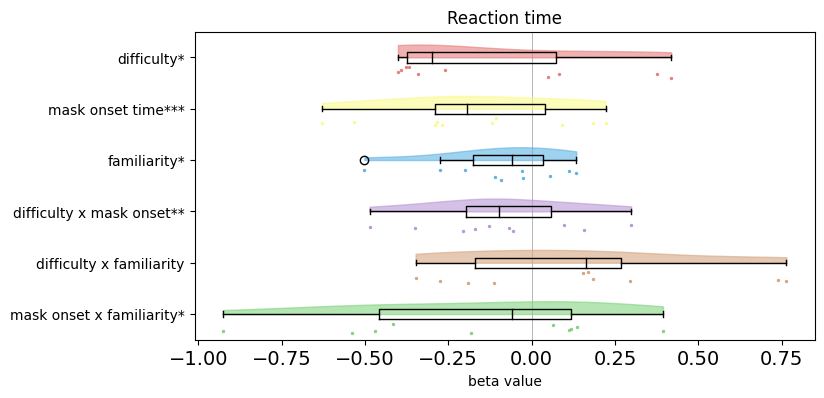

In [ ]:
data = all_weights
fig, ax = plt.subplots(figsize=(8,4))
plt.style.use('default')
# Step 1: get the x and y data
x1 = data.loc[data['variable'] == 'stim_diff', 'rt weight'].values
x2 = data.loc[data['variable'] == 'stim_dur', 'rt weight'].values
x3 = data.loc[data['variable'] == 'stim_fam', 'rt weight'].values
x4 = data.loc[data['variable'] == 'diff_x_dur', 'rt weight'].values
x5 = data.loc[data['variable'] == 'diff_x_fam', 'rt weight'].values
x6 = data.loc[data['variable'] == 'dur_x_fam', 'rt weight'].values
data_x = [x6, x5, x4, x3, x2, x1]
# boxplot
boxplot_colors = ['#82d47f', '#d6a681', '#b998d4', '#60B4E5', '#fafa8e', '#E6807E']
boxplot_widths = [0.2, 0.2, 0.2, 0.2, 0.2, 0.2]
medianprops = dict(color="black",linewidth=1)
bp = ax.boxplot(data_x, patch_artist = False, vert = False, widths=boxplot_widths, medianprops = medianprops)
#for patch, color in zip(bp['boxes'], boxplot_colors):
  #patch.set_facecolor(color)
  #patch.set_alpha(1)
# violin plots
violin_colors = ['#82d47f', '#d6a681', '#b998d4', '#60B4E5', '#fafa8e', '#E6807E']
vp = ax.violinplot(data_x, points=500, showmeans=False, showextrema=False, showmedians=False, vert=False)
# for seeing only upper half of the violin
for idx, b in enumerate(vp['bodies']):
  m = np.mean(b.get_paths()[0].vertices[:, 0])
  b.get_paths()[0].vertices[:, 1] = np.clip(b.get_paths()[0].vertices[:, 1], idx+1, idx+2)
  b.set_color(violin_colors[idx])
  b.set_alpha(0.6)
# scatter plot
scatter_colors = ['#82d47f', '#d6a681', '#b998d4', '#60B4E5', '#fafa8e', '#E6807E']
y_ticks = np.arange(1, 7)
y_offsets = [-0.25, -0.25, -0.25, -0.25, -0.25, -0.25]
for idx, groups in enumerate(data_x):
  y = np.full(len(groups), y_ticks[idx])
  y = y.astype(float)
  jitter = np.random.uniform(low=-0.15, high=0.075, size=len(groups))  # Add jitter
  y += y_offsets[idx] + jitter
  plt.scatter(groups, y, s=2, c=scatter_colors[idx])
  print(y)


plt.yticks(np.arange(1,7,1), ['mask onset x familiarity*', 'difficulty x familiarity', 'difficulty x mask onset**', 'familiarity*', 'mask onset time***', 'difficulty*'])
plt.xticks(fontsize=14)
plt.xlabel ('beta value')
plt.axvline(x = 0, color = 'black', alpha=0.4, lw = 0.5, zorder=-1)
plt.title('Reaction time')

fig.savefig('betas_rt.eps', format='eps')


[0.72600236 0.69853884 0.75520098 0.77837437 0.7558515  0.78107949
 0.64358625 0.76518402 0.63967097 0.62595543]
[1.73755786 1.67808568 1.82205495 1.72793295 1.63769246 1.7498657
 1.76572138 1.73796536 1.77678597 1.76467092]
[2.77906372 2.7834428  2.60772709 2.72591749 2.62739302 2.67118672
 2.64869103 2.69379714 2.69196935 2.72453998]
[3.65875419 3.7537783  3.71277338 3.74994459 3.79671453 3.62088375
 3.77526253 3.65304097 3.82278649 3.81854007]
[4.75094589 4.7091979  4.60864863 4.74351082 4.60036275 4.76597057
 4.80276934 4.68131515 4.75234475 4.77603277]
[5.62623414 5.63947004 5.68096128 5.73670717 5.70033272 5.74620518
 5.62265673 5.77258908 5.65329788 5.81230005]


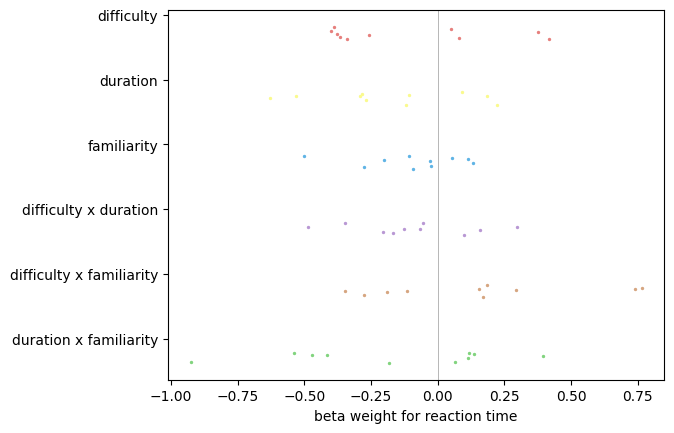

In [ ]:

# Step 1: get the x and y data
x1 = data.loc[data['variable'] == 'stim_diff', 'rt weight'].values
x2 = data.loc[data['variable'] == 'stim_dur', 'rt weight'].values
x3 = data.loc[data['variable'] == 'stim_fam', 'rt weight'].values
x4 = data.loc[data['variable'] == 'diff_x_dur', 'rt weight'].values
x5 = data.loc[data['variable'] == 'diff_x_fam', 'rt weight'].values
x6 = data.loc[data['variable'] == 'dur_x_fam', 'rt weight'].values
data_x = [x6, x5, x4, x3, x2, x1]
# boxplot
boxplot_colors = ['#82d47f', '#d6a681', '#b998d4', '#60B4E5', '#fafa8e', '#E6807E']
boxplot_widths = [0.2, 0.2, 0.2, 0.2, 0.2, 0.2]
medianprops = dict(color="black",linewidth=1)
bp = ax.boxplot(data_x, patch_artist = False, vert = False, widths=boxplot_widths, medianprops = medianprops)
#for patch, color in zip(bp['boxes'], boxplot_colors):
  #patch.set_facecolor(color)
  #patch.set_alpha(1)
# violin plots
violin_colors = ['#82d47f', '#d6a681', '#b998d4', '#60B4E5', '#fafa8e', '#E6807E']
vp = ax.violinplot(data_x, points=500, showmeans=False, showextrema=False, showmedians=False, vert=False)
# for seeing only upper half of the violin
for idx, b in enumerate(vp['bodies']):
  m = np.mean(b.get_paths()[0].vertices[:, 0])
  b.get_paths()[0].vertices[:, 1] = np.clip(b.get_paths()[0].vertices[:, 1], idx+1, idx+2)
  b.set_color(violin_colors[idx])
# scatterplots
scatter_colors = ['#82d47f', '#d6a681', '#b998d4', '#60B4E5', '#fafa8e', '#E6807E']
y_ticks = np.arange(1, 7)
y_offsets = [-0.25, -0.25, -0.25, -0.25, -0.25, -0.25]
for idx, groups in enumerate(data_x):
  y = np.full(len(groups), y_ticks[idx])
  y = y.astype(float)
  jitter = np.random.uniform(low=-0.15, high=0.075, size=len(groups))  # Add jitter
  y += y_offsets[idx] + jitter
  plt.scatter(groups, y, s=2, c=scatter_colors[idx])
  print(y)

plt.yticks(np.arange(1,7,1), ['duration x familiarity', 'difficulty x familiarity', 'difficulty x duration', 'familiarity', 'duration', 'difficulty'])
plt.xlabel ('beta weight for reaction time')
plt.axvline(x = 0, color = 'black', alpha=0.4, lw = 0.5, zorder=-1)
#plt.title('Raincloud plot of the distribution of beta weights for \nreaction time per variable across participants')



# Regression recognition test

In [ ]:
# import necessary packages for data
import numpy as np
import matplotlib.pyplot as plt
import pandas
from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import statsmodels.api as sm

In [ ]:
# this function prepares the data for the regression analyses, by calculating z-scores, coding dummy variables and creating interaction variables
def recog_analysis_prep(exp_data):

# drop all unneccesary rows and colums of exp_data, so only keep the factors and depended variables
  exp_data = exp_data.dropna(subset=['log10_rt_recog'])
  exp_data = exp_data[['stim_fam', 'recog.corr', 'log10_rt_recog', 'recog_ans']]

# calculate condition means, and stds and add them to exp_data
  # grouped_data = group_data_exp(exp_data)
  # exp_data = exp_data.merge(grouped_data, on=['stim_diff', 'stim_dur','stim_fam'])

# calculate z-scores of single trials
  #exp_data['z_acc'] = (exp_data['key_resp_dec.corr'] - exp_data['key_resp_dec.corr'].mean()) / exp_data['key_resp_dec.corr'].std()
  exp_data['recog_z_rt'] = (exp_data['log10_rt_recog'] - exp_data['log10_rt_recog'].mean()) / exp_data['log10_rt_recog'].std()

  exp_data['distractor'] = exp_data['stim_fam'].replace({'novel': 0.0, 'familiar': 0.0, 'distractor': 1.0})
  exp_data['novel'] = exp_data['stim_fam'].replace({'novel': 1.0, 'familiar': 0.0, 'distractor': 0.0})

  return exp_data

In [ ]:
# create dataframe with all data from the experiment
all_recog_data = pd.DataFrame()
all_recog_weights = pd.DataFrame(columns=['variable', 'rt weights', 'acc weights'])
recog_acc_weights = pd.DataFrame(columns=['variable', 'acc weight'])
recog_rt_weights = pd.DataFrame(columns=['variable', 'rt weight'])
c = 0 # counter looping through all paths
recog_r2_log = np.empty(10)
recog_r2_lin = np.empty(10)

# create array of paths to individual datafiles
paths = ['/content/drive/MyDrive/Experimental_data/03_RANDOM_1_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-04_14h40.54.589.csv',
         '/content/drive/MyDrive/Experimental_data/04_RANDOM_2_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_14h26.22.381.csv',
         '/content/drive/MyDrive/Experimental_data/05_RANDOM_3_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_15h03.39.716.csv',
         '/content/drive/MyDrive/Experimental_data/06_RANDOM_4_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_13h51.56.087.csv',
         '/content/drive/MyDrive/Experimental_data/07_RANDOM_5_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-07_18h46.26.064.csv',
         '/content/drive/MyDrive/Experimental_data/09_RANDOM_2_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-13_19h00.14.866.csv',
         '/content/drive/MyDrive/Experimental_data/10_RANDOM_3_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-13_17h16.42.809.csv',
         '/content/drive/MyDrive/Experimental_data/11_RANDOM_4_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-14_10h09.37.881.csv',
         '/content/drive/MyDrive/Experimental_data/12_RANDOM_5_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-17_18h42.29.462.csv',
         '/content/drive/MyDrive/Experimental_data/13_RANDOM_1_DAY2_JetLambers_PsychopyExperiment_BachelorThesis_2023-04-18_16h35.42.026.csv']

# preprocess individual data
for i in range(3,14):

  if i == 8: # skip participant who's data was deemed unreliable
    continue

  if i in [3, 5, 7, 9, 11]: # odd participants with normal response buttons
    exp_data = preprocess_data_2N(paths[c]) # see preprocess code


  if i in [4, 6, 10, 12, 13]: # even participants with reversed response buttons
    exp_data = preprocess_data_2R(paths[c])

  exp_data = recog_analysis_prep(exp_data)
  exp_data.reindex(["distractor", "novel", "recog.corr", "recog_z_rt", "recog_ans"], axis="columns")

# define the predictors and targets
  y1 = exp_data['recog_ans'].astype(int)
  y2 = exp_data['recog_z_rt'].astype(int)
  X2 = exp_data[['distractor', 'novel']].astype(int)

  acc_model = LogisticRegression()
  acc_model.fit(X2, y1)
  acc_intercept = acc_model.intercept_
  acc_coef = acc_model.coef_[0].flatten()
  acc_coef = np.insert(acc_coef, 0, acc_intercept)

  acc_summ = pd.DataFrame({
      'variable': ['intercept', 'distractor', 'novel'],
      'acc weight': acc_coef
  })
  recog_acc_weights = pd.concat([recog_acc_weights, acc_summ], ignore_index=True)
  recog_r2_log[c] = acc_model.score(X2, y1)


# set up a linear multiple regression with stim_diff, stim_dur and stim_fam as predictors and rt as target
  # X1 = sm.add_constant(X)
  rt_model = LinearRegression()
  rt_model.fit(X2, y2)
  rt_intercept = rt_model.intercept_
  rt_coef = rt_model.coef_.flatten()
  rt_coef = np.insert(rt_coef, 0, rt_intercept)
  rt_summ = pd.DataFrame({
      'variable': ['intercept', 'distractor', 'novel'],
      'rt weight': rt_coef
  })
  recog_rt_weights = pd.concat([recog_rt_weights, rt_summ], ignore_index=True)
  recog_r2_lin[c] = rt_model.score(X2, y2)

# set counter to next path index
  c += 1

  all_recog_data = pd.concat([all_recog_data, exp_data], ignore_index=True)
  all_recog_weights = pd.concat([recog_acc_weights, recog_rt_weights['rt weight']], axis=1)

recog_weights = all_recog_weights.groupby('variable', sort=False)[['acc weight', 'rt weight']].mean().reset_index()
recog_sem = all_recog_weights.groupby('variable', sort=False)[['acc weight', 'rt weight']].sem().reset_index()
recog_weights['ans sem'] = recog_sem['acc weight']
recog_weights['rt sem'] = recog_sem['rt weight']

obs_r2_acc_recog = recog_r2_log.mean()
obs_r2_rt_recog = recog_r2_lin.mean()

print(recog_weights)
print(obs_r2_acc_recog)

<ipython-input-22-f95c55a41bc3>:74: FutureWarning: In a future version, object-dtype columns with all-bool values will not be included in reductions with bool_only=True. Explicitly cast to bool dtype instead.
  all_recog_data = pd.concat([all_recog_data, exp_data], ignore_index=True)


     variable  acc weight  rt weight   ans sem    rt sem
0   intercept    1.013736  -0.018754  0.187337  0.053530
1  distractor   -1.522940   0.130266  0.207216  0.028737
2       novel   -1.522788   0.072015  0.216065  0.027336
0.6977330508156353


In [ ]:
# create a null distribution dataframe
recog_null_distribution = pd.DataFrame(columns = ['acc weight', 'rt weight'])
r2_acc_null_recog = np.empty(10000)
r2_rt_null_recog = np.empty(10000)
# loop though data
for k in range(10000):
  c = 0 # counter looping through all paths
  recog_acc_weights = pd.DataFrame(columns=['variable', 'acc weight'])
  recog_rt_weights = pd.DataFrame(columns=['variable', 'rt weight'])
  r2_log = np.empty(10)
  r2_lin = np.empty(10)

# preprocess individual data
  for i in range(3,14):

    if i == 8: # skip participant who's data was deemed unreliable
      continue

    if i in [3, 5, 7, 9, 11]: # odd participants with normal response buttons
      exp_data = preprocess_data_2N(paths[c]) # see preprocess code


    if i in [4, 6, 10, 12, 13]: # even participants with reversed response buttons
      exp_data = preprocess_data_2R(paths[c])

    exp_data = recog_analysis_prep(exp_data)
    exp_data.reindex(["distractor", "novel", "recog_ans", "recog_z_rt", "recog.corr"], axis="columns")

  # randomly shuffle condition labels
    exp_data['distractor'] = exp_data['distractor'].sample(frac=1).values
    exp_data['novel'] = exp_data['novel'].sample(frac=1).values

    y1 = exp_data['recog_ans'].astype(int)
    y2 = exp_data['recog_z_rt'].astype(int)
    X2 = exp_data[['distractor', 'novel']].astype(int)

    acc_model = LogisticRegression()
    acc_model.fit(X2, y1)
    acc_intercept = acc_model.intercept_
    acc_coef = acc_model.coef_[0].flatten()
    acc_coef = np.insert(acc_coef, 0, acc_intercept)

    acc_summ = pd.DataFrame({
        'variable': ['intercept', 'distractor', 'novel'],
        'acc weight': acc_coef
    })
    recog_acc_weights = pd.concat([recog_acc_weights, acc_summ], ignore_index=True)
    r2_log[c] = acc_model.score(X2, y1)

  # set up a linear multiple regression with stim_diff, stim_dur and stim_fam as predictors and rt as target
    rt_model = LinearRegression()
    rt_model.fit(X2, y2)
    rt_intercept = rt_model.intercept_
    rt_coef = rt_model.coef_.flatten()
    rt_coef = np.insert(rt_coef, 0, rt_intercept)
    rt_summ = pd.DataFrame({
        'variable': ['intercept', 'distractor', 'novel'],
        'rt weight': rt_coef
    })
    recog_rt_weights = pd.concat([recog_rt_weights, rt_summ], ignore_index=True)

    all_recog_weights = pd.concat([recog_acc_weights, recog_rt_weights['rt weight']], axis=1)
    r2_lin[c] = rt_model.score(X2, y2)

  # set counter to next path index
    c += 1

# get the mean of the weights and add that to null distribution
  all_recog_weights2 = all_recog_weights.groupby('variable', sort=False)[['acc weight', 'rt weight']].mean()
  recog_null_distribution = pd.concat([recog_null_distribution, all_recog_weights2])
  r2_acc_null_recog = r2_log.mean()
  r2_rt_null_recog = r2_lin.mean()

<ipython-input-4-db715a8f1a40>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['stim_dur'] = data['stim_dur'].replace({1.0: 'short', 2.0: 'long'})
<ipython-input-21-2c0e0f50828e>:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exp_data['recog_z_rt'] = (exp_data['log10_rt_recog'] - exp_data['log10_rt_recog'].mean()) / exp_data['log10_rt_recog'].std()
<ipython-input-21-2c0e0f50828e>:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_index

In [ ]:
recog_acc_p = (r2_acc_null_recog >= obs_r2_acc_recog).mean()
recog_rt_p = (r2_rt_null_recog >= obs_r2_rt_recog).mean()
print(f"p value of acc recog model: {recog_acc_p}")
print(f"p value of rt recog model: {recog_rt_p}")

p value of acc recog model: 0.0
p value of rt recog model: 0.0


In [ ]:
for var in recog_weights['variable']:
    observed_acc_weight = recog_weights.loc[recog_weights['variable'] == var, 'acc weight'].values[0]
    observed_rt_weight = recog_weights.loc[recog_weights['variable'] == var, 'rt weight'].values[0]

    # Compare observed beta weights with null distribution
    if observed_acc_weight >= 0:
      acc_p_value = (recog_null_distribution.loc[var, 'acc weight'] >= observed_acc_weight).mean()
    else:
      acc_p_value = (recog_null_distribution.loc[var, 'acc weight'] <= observed_acc_weight).mean()

    if observed_rt_weight >= 0:
      rt_p_value = (recog_null_distribution.loc[var, 'rt weight'] >= observed_rt_weight).mean()
    else:
      rt_p_value = (recog_null_distribution.loc[var, 'rt weight'] <= observed_rt_weight).mean()

    recog_weights.loc[recog_weights['variable'] == var, 'acc p'] = acc_p_value
    recog_weights.loc[recog_weights['variable'] == var,'rt p'] = rt_p_value

display(recog_weights)

,variable,acc weight,rt weight,ans sem,rt sem,acc p,rt p
0,intercept,1.013736,-0.018754,0.187337,0.053530,0.0,0.00
1,distractor,-1.522940,0.130266,0.207216,0.028737,0.0,0.00
2,novel,-1.522788,0.072015,0.216065,0.027336,0.0,0.01


[0.78807705 0.60876478 0.7242858  0.77620951 0.66213436 0.71521028
 0.66472929 0.75633743 0.78255992 0.7284952 ]
[1.76328231 1.65737964 1.66386573 1.72450874 1.67524411 1.60898022
 1.68269039 1.75933383 1.77090715 1.73118252]


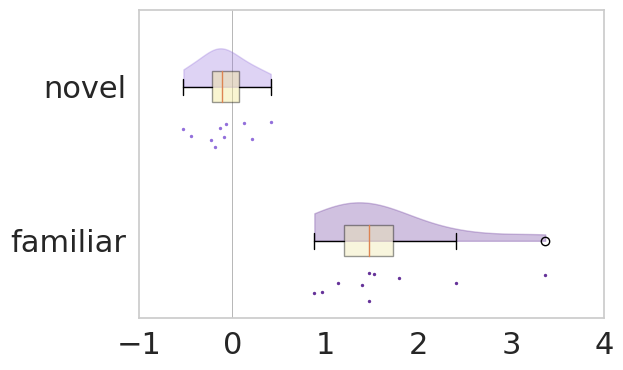

In [ ]:
data = all_recog_weights
fig, ax = plt.subplots(figsize=(6,4))
# Step 1: get the x and y data
x1 = data.loc[data['variable'] == 'familiar', 'acc weight'].values
x2 = data.loc[data['variable'] == 'novel', 'acc weight'].values
data_x = [x1, x2]
# boxplot
boxplot_colors = ['palegoldenrod', 'khaki']
boxplot_widths = [0.2, 0.2]
bp = ax.boxplot(data_x, patch_artist = True, vert = False, widths=boxplot_widths)
for patch, color in zip(bp['boxes'], boxplot_colors):
  patch.set_facecolor(color)
  patch.set_alpha(0.4)
# violin plots
violin_colors = ['rebeccapurple', 'mediumpurple']
vp = ax.violinplot(data_x, points=500, showmeans=False, showextrema=False, showmedians=False, vert=False)
# for seeing only upper half of the violin
for idx, b in enumerate(vp['bodies']):
  m = np.mean(b.get_paths()[0].vertices[:, 0])
  b.get_paths()[0].vertices[:, 1] = np.clip(b.get_paths()[0].vertices[:, 1], idx+1, idx+2)
  b.set_color(violin_colors[idx])
# scatterplots
scatter_colors = ['rebeccapurple', 'mediumpurple']
y_ticks = np.arange(1, 3)
y_offsets = [-0.25, -0.25]
for idx, groups in enumerate(data_x):
  y = np.full(len(groups), y_ticks[idx])
  y = y.astype(float)
  jitter = np.random.uniform(low=-0.15, high=0.075, size=len(groups))  # Add jitter
  y += y_offsets[idx] + jitter
  plt.scatter(groups, y, s=2, c=scatter_colors[idx])
  print(y)

plt.yticks(np.arange(1,3,1), ['familiar', 'novel'])
plt.xlim(-1, 4)
plt.grid(False)
plt.axvline(x = 0, color = 'black', alpha=0.4, lw = 0.5, zorder=-1)
#plt.xlabel ('Beta weight for \nproportion familiar responses')
#plt.title('Raincloud plot of the beta weights for accuracy weights per familiarity condition on the recognition test')


# Stuff that is not needed anymore

In [ ]:
def d_prime (data):
  # transform categories from strings to numbers (check for spaces)
  data['stim_cat'] = data['stim_cat'].replace({'bear': 1, 'elephant': 2, 'face': 3, 'car': 4, 'dog': 5, 'apple': 6, 'chair': 7, 'plane': 8, 'bird': 9, 'zebra': 10})
  data['stim_cat'] = data['stim_cat'].replace({' bear': 1, ' elephant': 2, ' face': 3, ' car': 4, ' dog': 5, ' apple': 6, ' chair': 7, ' plane': 8, ' bird': 9, ' zebra': 10})
  data['dist'] = data['dist'].replace({'bear': 1, 'elephant': 2, 'face': 3, 'car': 4, 'dog': 5, 'apple': 6, 'chair': 7, 'plane': 8, 'bird': 9, 'zebra': 10})
  data['dist'] = data['dist'].replace({' bear': 1, ' elephant': 2, ' face': 3, ' car': 4, ' dog': 5, ' apple': 6, ' chair': 7, ' plane': 8, ' bird': 9, ' zebra': 10})
# calculate mean hit rate per image
for k in range(len(data)):
  hitrate = 0
# loop through all possible objects
  for i in range(10):
  # if distractor is the taget object, do not calculate proportion of correct answers
    if dist == i:
      continue
    else:
      hitrate = hitrate +

SyntaxError: ignored

In [ ]:
# create aggregated data by hand
mean_data = pd.DataFrame(columns=['stim_diff', 'stim_dur', 'stim_fam'])

for stim_diff in all_data['stim_diff'].unique():
    for stim_dur in all_data['stim_dur'].unique():
         for stim_fam in all_data['stim_fam'].unique():
            conditions = all_data[(all_data['stim_diff'] == stim_diff) &
                          (all_data['stim_dur'] == stim_dur) &
                          (all_data['stim_fam'] == stim_fam) &
                          (~all_data['mean_exp_rt'].isna()) &  # exlude missing values from aggregated data
                          (~all_data['mean_exp_acc'].isna())]
            # calculate the mean reaction time and accuracy for each condition (combination of factors)
            mean_exp_rt = conditions['mean_exp_rt'].mean()
            std_exp_rt = conditions['std_exp_rt'].mean()
            sem_exp_rt = conditions['mean_exp_rt'].sem()
            mean_exp_acc = conditions['mean_exp_acc'].mean()
            std_exp_acc = conditions['std_exp_acc'].mean()
            sem_exp_acc = conditions['mean_exp_acc'].sem()
            # add means to dataframe
            mean_data = mean_data.append({'stim_diff': stim_diff,
                                            'stim_dur': stim_dur,
                                            'stim_fam': stim_fam,
                                            'grand_mean_rt': mean_exp_rt,
                                            'grand_mean_acc': mean_exp_acc,
                                            'grand_std_rt' : std_exp_rt,
                                            'grand_std_acc': std_exp_acc,
                                            'total_sem_rt' : sem_exp_rt,
                                            'total_sem_acc' : sem_exp_acc},
                                            ignore_index=True)

In [ ]:
def exp_rt_plot(data, ax=None):
    # group the data by condition
    grouped = data.groupby(['stim_fam']).mean()  # just the familiarization

    # create the plot
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 6))

    # plot the bars
    grouped['mean_exp_rt'].plot(kind='bar', ax=ax)

    x_values = np.arange(len(grouped))
    ax.bar(x_values, grouped['mean_exp_rt'], yerr=grouped['std_exp_rt'], capsize=3)

    # add horizontal lines
    ax.axhline(y=0.5, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.55, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.6, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.65, color='grey', linewidth=0.5, linestyle='--', zorder=-1)

    # set the y-axis limits to obtain the right scale and tick labels
    ax.set_ylim(0.4, 0.7)
    ax.set_yticks([0.5, 0.55, 0.6, 0.65, 0.7])
    ax.set_yticklabels(['0.5', '0.55', '0.6', '0.65', '0.7'])

    # set the x- and y-axis labels and title
    ax.set_xlabel('Condition')
    ax.set_ylabel('Reaction Time')
    #ax.set_title('Mean RT by condition')

    # return the figure object
    return ax


In [ ]:
# color still needs to be added!!!
def exp_acc_plot(dataframe, ax=None):
    # group by the condition columns and calculate the mean of the other columns
    grouped = dataframe.groupby(['stim_diff', 'stim_dur', 'stim_fam']).mean()

    # create the plot
    if ax is None:
      fig, ax = plt.subplots(figsize=(5, 3))

    # add the bars '
    grouped['mean_exp_acc'].plot(kind='bar', ax=ax)
    #x_values = np.arange(len(grouped))
    #ax.bar(x_values, grouped['mean_exp_acc'], yerr=grouped['std_exp_acc'], capsize=3)

    # add horzontal lines for clarity
    ax.axhline(y=0.5, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.55, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.6, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.65, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.7, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.75, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.8, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.85, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.9, color='grey', linewidth=0.5, linestyle='--', zorder=-1)
    ax.axhline(y=0.95, color='grey', linewidth=0.5, linestyle='--', zorder=-1)

    # set the y-axis limits to obtain right scale and tick labels
    ax.set_ylim(0.45, 1.0)
    ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_yticklabels(['0.50', '0.60', '0.70', '0.80', '0.90', '1.0'])

    # set the x- and y-axis labels and title
    ax.set_xlabel('Condition')
    ax.set_ylabel('Accuracy')
    #ax.set_title('Accuracy per (difficulty x duration x familiary) condition')

    return ax


In [ ]:
# create dataframes for the target variables
acc_target = pd.DataFrame(all_data['z_acc'], columns=['z_acc'])
#rt_target = pd.DataFrame(all_data['z_rt'], columns=['z_rt'])

# create a dataframe for the predictors
pred = all_data[['stim_diff', 'stim_dur', 'stim_fam']]
pred['diff_x_dur'] = pred['stim_diff'] * pred['stim_dur']
pred['diff_x_fam'] = pred['stim_diff'] * pred['stim_fam']
pred['dur_x_fam'] = pred['stim_dur'] * pred['stim_fam']

y = acc_target['z_acc']
X = pred[['stim_diff', 'stim_dur', 'stim_fam', 'diff_x_dur', 'diff_x_fam', 'dur_x_fam']]
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()

summ = pd.DataFrame(model.tvalues, columns=['beta-weight'])
display(summ)
model.summary()


In [ ]:
x = pred[['stim_diff', 'stim_dur', 'stim_fam']]
y = acc_target['mean_exp_acc']
x = sm.add_constant(x)
model = sm.OLS(y, x).fit()
predictions = model.predict(x)
model.summary()

# Mask processing

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numpy import asarray
from PIL import Image
from PIL import ImageDraw
from PIL import ImageFilter
from google.colab import files


for i in range(71,81):
  # create black image
  #arr = np.full((217, 217, 3), 0, dtype=np.uint8) # this is your mask image (currently black)
  arr = asarray(Image.open(f"mask_{i}.jpg"))
  imgsize = arr.shape[:2]


  outerColor = (127,127,127) # this is your background color (currently white)
  innerBoundary = 90 # this defines the area of the mask unaffected by the gradient (needs tweaking)
  outerBoundary = 108 # this defines the area of the background unaffected by the gradient (needs tweaking)
  gradScale = 1/(outerBoundary-innerBoundary)

  for y in range(imgsize[1]):
    for x in range(imgsize[0]):
      # find the distance to the centre
      distanceToCenter = np.sqrt((x - imgsize[0]//2) **2 + (y - imgsize[1]//2) ** 2)

      if distanceToCenter > innerBoundary:
        if distanceToCenter > outerBoundary:
          arr[y,x] = outerColor

        else:
          # scale from 0 to innerColor
          colorScale = (distanceToCenter-innerBoundary)*gradScale

          #calculate r, g, b values
          r = outerColor[0] * colorScale + arr[y,x,0] * (1-colorScale)
          g = outerColor[1] * colorScale + arr[y,x,1] * (1-colorScale)
          b = outerColor[2] * colorScale + arr[y,x,2] * (1-colorScale)

          # print r, g, and b
          arr[y,x] = (int(r), int(g), int(b))

  plt.imsave(f"mask_stim{i}.jpg",arr)

  files.download(f"mask_stim{i}.jpg")

FileNotFoundError: ignored